In [5]:
import sys
from pathlib import Path

# Arahkan Python ke folder utama proyek agar folder 'src' terbaca
root_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.features import clean_raw_dataframe

raw_df = pd.read_csv(root_dir / "data" / "raw.csv")
print("Ukuran data mentah:", raw_df.shape)
print("\nVariasi nama stasiun mentah (16 variasi):")
print(raw_df["stasiun"].value_counts())

print("\nNilai PM2.5 tidak wajar (< 0):")
print(raw_df[raw_df["pm25_ugm3"] < 0]["pm25_ugm3"].value_counts())

Ukuran data mentah: (87650, 8)

Variasi nama stasiun mentah (16 variasi):
stasiun
Dago               17025
Cibeureum          17011
Soekarno-Hatta     16997
Ujungberung        16995
Antapani           16987
Ujung Berung         286
antapani             285
ujungberung          264
Cibeureum            260
dago                 259
ANTAPANI             258
cibeureum            255
DAGO                 243
Soekarno-Hatta       177
Soekarno Hatta       175
SOETTA               173
Name: count, dtype: int64

Nilai PM2.5 tidak wajar (< 0):
pm25_ugm3
-999.0    173
Name: count, dtype: int64


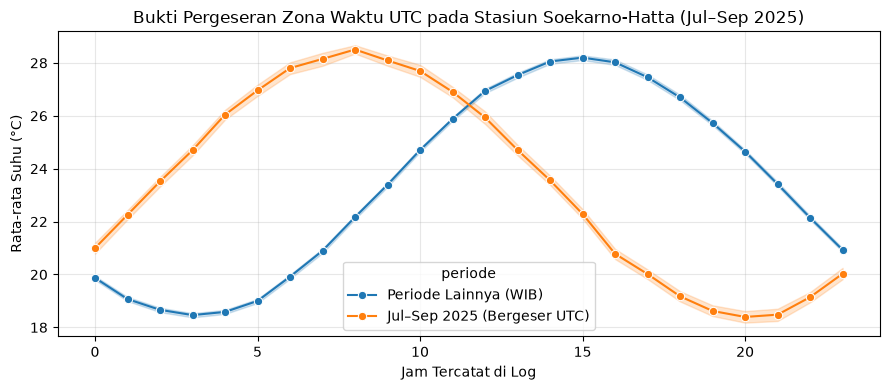

In [6]:
raw_df["dt"] = pd.to_datetime(raw_df["waktu"])
raw_df["jam"] = raw_df["dt"].dt.hour

# Bandingkan pola suhu harian Soekarno-Hatta pada Juli-Sept 2025 vs bulan lainnya
sh = raw_df[raw_df["stasiun"].str.lower().str.contains("soekarno|soetta")].copy()
sh["periode"] = sh["dt"].between("2025-07-01", "2025-09-30").map(
    {True: "Jul–Sep 2025 (Bergeser UTC)", False: "Periode Lainnya (WIB)"}
)

plt.figure(figsize=(9, 4))
sns.lineplot(data=sh, x="jam", y="suhu_C", hue="periode", marker="o")
plt.title("Bukti Pergeseran Zona Waktu UTC pada Stasiun Soekarno-Hatta (Jul–Sep 2025)")
plt.xlabel("Jam Tercatat di Log")
plt.ylabel("Rata-rata Suhu (°C)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(root_dir / "docs" / "eda_anomali_utc.png", dpi=150)
plt.show()

Ukuran data bersih: (87600, 10)

Jumlah missing values setelah pembersihan:
waktu                    0
stasiun                  0
pm25_ugm3              750
suhu_C                 491
kelembaban_pct         491
kecepatan_angin_ms    1223
arah_angin_deg         348
curah_hujan_mm         348
dt                     348
jam                    348
dtype: int64


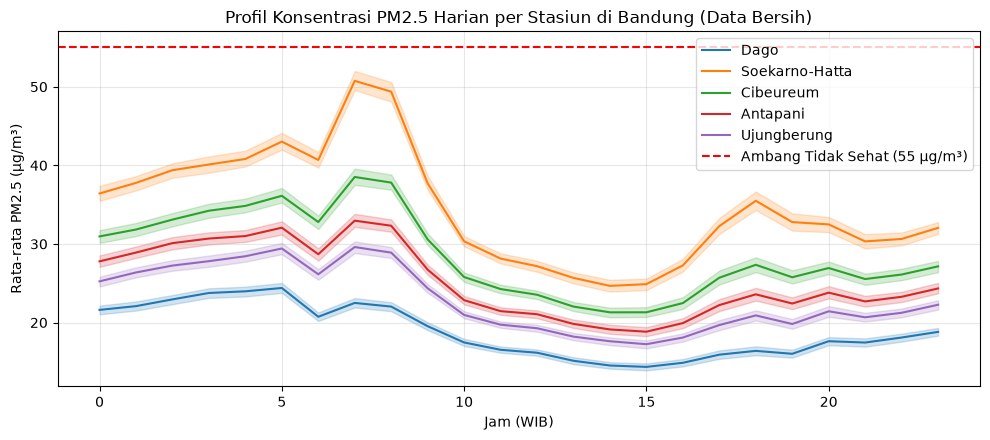

In [7]:
clean_df = clean_raw_dataframe(raw_df)
print("Ukuran data bersih:", clean_df.shape)
print("\nJumlah missing values setelah pembersihan:")
print(clean_df.isnull().sum())

clean_df["jam"] = clean_df["waktu"].dt.hour

plt.figure(figsize=(10, 4.5))
sns.lineplot(data=clean_df, x="jam", y="pm25_ugm3", hue="stasiun")
plt.axhline(55, color="red", linestyle="--", label="Ambang Tidak Sehat (55 µg/m³)")
plt.title("Profil Konsentrasi PM2.5 Harian per Stasiun di Bandung (Data Bersih)")
plt.xlabel("Jam (WIB)")
plt.ylabel("Rata-rata PM2.5 (µg/m³)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(root_dir / "docs" / "eda_profil_pm25.png", dpi=150)
plt.show()